In [9]:
from nilearn.input_data import nifti_masker

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from nilearn import datasets
import nibabel as nib
%pylab inline

Populating the interactive namespace from numpy and matplotlib


In [11]:
n_subjects=30
oasis_dataset = datasets.fetch_oasis_vbm(n_subjects=n_subjects)
gray_matter_map_filenames = oasis_dataset.gray_matter_maps

/home/qinqian/anaconda3/lib/python3.6/site-packages/numpy/lib/npyio.py:2266: VisibleDeprecationWarning: Reading unicode strings without specifying the encoding argument is deprecated. Set the encoding, use None for the system default.
  output = genfromtxt(fname, **kwargs)


In [12]:
a = nib.load(gray_matter_map_filenames[0])

<OrthoSlicer3D: /home/qinqian/nilearn_data/oasis1/OAS1_0001_MR1/mwrc1OAS1_0001_MR1_mpr_anon_fslswapdim_bet.nii.gz (91, 109, 91)>

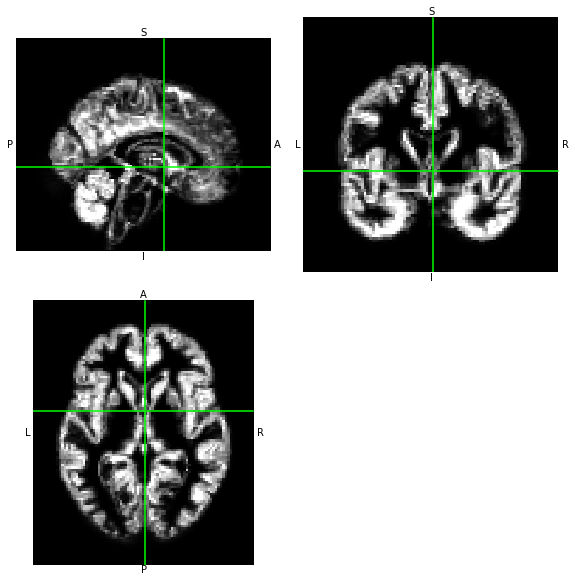

In [13]:
a.orthoview()

In [15]:
masker = nifti_masker.NiftiMasker(
    standardize=False,
    smoothing_fwhm=2,
    memory='nilearn_cache')  # cache options
gm_maps_masked = masker.fit_transform(gray_matter_map_filenames)
n_samples, n_features = gm_maps_masked.shape
print("%d samples, %d features" % (n_subjects, n_features))

30 samples, 902629 features


In [16]:
age = oasis_dataset.ext_vars['age']

In [17]:
print("ANOVA + SVR")
# Define the prediction function to be used.
# Here we use a Support Vector Classification, with a linear kernel
from sklearn.svm import SVR
svr = SVR(kernel='linear')

# Dimension reduction
from sklearn.feature_selection import VarianceThreshold, SelectKBest, \
        f_regression

# Remove features with too low between-subject variance
variance_threshold = VarianceThreshold(threshold=.01)

# Here we use a classical univariate feature selection based on F-test,
# namely Anova.
feature_selection = SelectKBest(f_regression, k=2000)

# We have our predictor (SVR), our feature selection (SelectKBest), and now,
# we can plug them together in a *pipeline* that performs the two operations
# successively:
from sklearn.pipeline import Pipeline
anova_svr = Pipeline([
            ('variance_threshold', variance_threshold),
            ('anova', feature_selection),
            ('svr', svr)])

ANOVA + SVR


In [18]:
### Fit and predict
anova_svr.fit(gm_maps_masked, age)
age_pred = anova_svr.predict(gm_maps_masked)

In [19]:
import pandas as pd
z = pd.DataFrame({'real': age, 'pred': age_pred})
z

,pred,real
0,73.899727,74
1,55.099922,55
2,72.957558,73
3,27.900177,28
4,17.900077,18
5,29.006472,24
6,21.100312,21
7,20.652302,20
8,74.099866,74
9,49.148828,52


In [21]:
coef = svr.coef_
print(coef.shape)

# reverse feature selection
coef = feature_selection.inverse_transform(coef)
print(coef.shape)

coef = variance_threshold.inverse_transform(coef)
print(coef.shape)

weight_img = masker.inverse_transform(coef)

(1, 2000)
(1, 133542)
(1, 902629)


In [22]:
print(weight_img.shape)

(91, 109, 91, 1)


/home/qinqian/anaconda3/lib/python3.6/site-packages/nilearn-0.4.1-py3.6.egg/nilearn/plotting/__init__.py:20: UserWarning: 
This call to matplotlib.use() has no effect because the backend has already
been chosen; matplotlib.use() must be called *before* pylab, matplotlib.pyplot,
or matplotlib.backends is imported for the first time.

The backend was *originally* set to 'module://ipykernel.pylab.backend_inline' by the following code:
  File "/home/qinqian/anaconda3/lib/python3.6/runpy.py", line 193, in _run_module_as_main
    "__main__", mod_spec)
  File "/home/qinqian/anaconda3/lib/python3.6/runpy.py", line 85, in _run_code
    exec(code, run_globals)
  File "/home/qinqian/anaconda3/lib/python3.6/site-packages/ipykernel_launcher.py", line 16, in <module>
    app.launch_new_instance()
  File "/home/qinqian/anaconda3/lib/python3.6/site-packages/traitlets/config/application.py", line 658, in launch_instance
    app.start()
  File "/home/qinqian/anaconda3/lib/python3.6/site-packages/ipykern

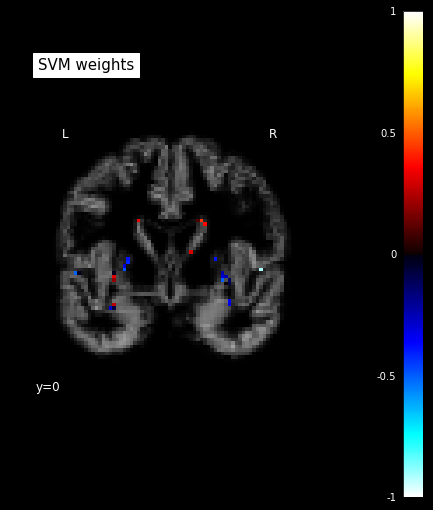

In [23]:
# Create the figure
from nilearn.plotting import plot_stat_map, show
bg_filename = gray_matter_map_filenames[0]
z_slice = 0

fig = plt.figure(figsize=(5.5, 7.5), facecolor='k')
# Hard setting vmax to highlight weights more
display = plot_stat_map(weight_img, bg_img=bg_filename,
                        display_mode='y', cut_coords=[z_slice],
                        figure=fig, vmax=1)
display.title('SVM weights', y=1.2)

In [24]:
# Statistical inference
from nilearn.mass_univariate import permuted_ols
print(gm_maps_masked.shape)
data = variance_threshold.fit_transform(gm_maps_masked)

(30, 902629)


In [25]:
data.shape

(30, 133542)

In [26]:
neg_log_pvals, t_scores_original_data, _ = permuted_ols(
    age, data,  # + intercept as a covariate by default
    n_perm=500,  # 1,000 in the interest of time; 10000 would be better
    n_jobs=4)  # can be changed to use more CPUs

In [27]:
signed_neg_log_pvals = neg_log_pvals * np.sign(t_scores_original_data)

In [28]:
signed_neg_log_pvals.shape

(1, 133542)

In [29]:
signed_neg_log_pvals_unmasked = masker.inverse_transform(
    variance_threshold.inverse_transform(signed_neg_log_pvals))


/home/qinqian/anaconda3/lib/python3.6/site-packages/matplotlib/cbook/deprecation.py:107: MatplotlibDeprecationWarning: Adding an axes using the same arguments as a previous axes currently reuses the earlier instance.  In a future version, a new instance will always be created and returned.  Meanwhile, this warning can be suppressed, and the future behavior ensured, by passing a unique label to each axes instance.
  warnings.warn(message, mplDeprecation, stacklevel=1)


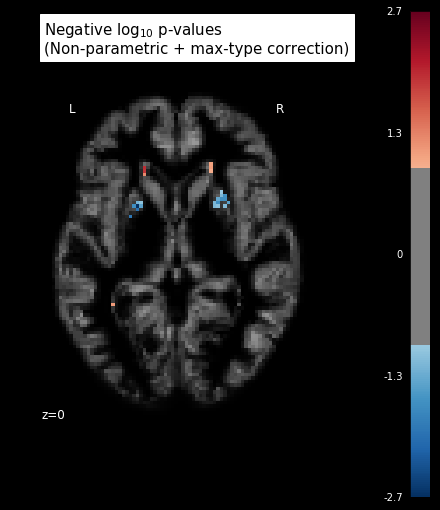

In [30]:
# Show results
threshold = -np.log10(0.1)  # 10% corrected

fig = plt.figure(figsize=(5.5, 7.5), facecolor='k')

display = plot_stat_map(signed_neg_log_pvals_unmasked, bg_img=bg_filename,
                        threshold=threshold, cmap=plt.cm.RdBu_r,
                        display_mode='z', cut_coords=[z_slice],
                        figure=fig)
title = ('Negative $\log_{10}$ p-values'
         '\n(Non-parametric + max-type correction)')
display.title(title, y=1.2)


In [47]:
gm = nib.load('gray_matter_mask.nii.gz')
gm_masker = nifti_masker.NiftiMasker(
    gm,
    standardize=True,
    smoothing_fwhm=2,
    memory='nilearn_cache'
)

demog = pd.read_table('mut_comparison_pws_t2_meta.xls')
niis = pd.read_table('mut_files.xls').iloc[:,0].tolist()
print(niis)

['../data/fmri_nii/mut/OAx_T2__1m_10888740_20170705_3__F__39.5714285714__del___jacob.nii.gz', '../data/fmri_nii/mut/OAx_T2FLAIR__1m_10888740_20170705_5__F__39.5714285714__del___jacob.nii.gz', '../data/fmri_nii/mut/OAx_T2__1m_10937378_20171007_4__F__39.7142857143__del___jacob.nii.gz', '../data/fmri_nii/mut/OAx_T2FLAIR__1m_10937378_20171007_6__F__39.7142857143__del___jacob.nii.gz', '../data/fmri_nii/mut/OAx_T2_FLAIR_10705248_20160520_5__F__42.5714285714__del___jacob.nii.gz', '../data/fmri_nii/mut/OAx_T2__1m_10767252_20160929_3__F__44.4285714286__del___jacob.nii.gz', '../data/fmri_nii/mut/OAx_T2FLAIR__1m_10767252_20160929_6__F__44.4285714286__del___jacob.nii.gz', '../data/fmri_nii/mut/OAx_T2_FLAIR_10825774_20170524_6__F__60.4285714286__del___jacob.nii.gz', '../data/fmri_nii/mut/OAx_T2_FLAIR_10722630_20160702_6__M__41.1428571429__del___jacob.nii.gz', '../data/fmri_nii/mut/OAx_T2_FLAIR_10632193_20151207_4__M__52.0__del___jacob.nii.gz', '../data/fmri_nii/mut/OAx_T2_FLAIR_10726855_20160711_6_

In [48]:
gms = gm_masker.fit_transform(niis)
print(gms.shape)

(31, 268634)


In [65]:
var_filter = VarianceThreshold(threshold=1)
data = var_filter.fit_transform(gms)
print(data.shape)

demog_scale = (demog - demog.mean(axis=0))/demog.std(axis=0)
mutation = demog.iloc[:, 0].values
confound = demog.iloc[:, [1,2]].values
print(demog_scale.head())
mutation = demog_scale.iloc[:, 0].values
confound = demog_scale.iloc[:, [1,2]].values

(31, 104926)
    mutation  lm_gender   log_cga
3  -0.892728  -1.425573 -0.840045
30 -0.892728  -1.425573 -0.840045
4  -0.892728  -1.425573 -0.834079
31 -0.892728  -1.425573 -0.834079
10 -0.892728  -1.425573 -0.714760


In [66]:
print(mutation.shape)
print(confound.shape)
gm_neg_log_pvals, gm_t_scores_original_data, _ = permuted_ols(
    mutation, data, confound,  # + intercept as a covariate by default
    n_perm=1000,  # 1,000 in the interest of time; 10000 would be better
    model_intercept=True,
    n_jobs=28)

(31,)
(31, 2)


[[-0. -0. -0. ... -0. -0. -0.]]
(181, 217, 181, 1)
(181, 217, 181)


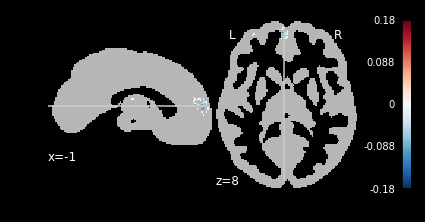

In [76]:
final = gm_neg_log_pvals * np.sign(gm_t_scores_original_data)
print(final)
final_unmasked = gm_masker.inverse_transform(var_filter.inverse_transform(final))
print(final_unmasked.shape)
print(gm.shape)
plot_stat_map(final_unmasked, bg_img = gm, cmap=plt.cm.RdBu_r,colorbar=True,
              display_mode='xz')

In [72]:
?plot_stat_map
